# GHAgentCI 4: gh-aw manifests and workflow content

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/unlv-evol/cai-miner/blob/main/notebooks/04-gh-aw-and-workflow-content.ipynb)

GitHub Agentic Workflows (gh-aw) are written as Markdown files with a YAML frontmatter (*sources*) and compiled into ordinary Actions workflows (*lock files*, `*.lock.yml`). The `ghaw_manifests` table records the declared configuration of both. The second half of this notebook reads the actual YAML of any revision from `content.tar.gz`.

**Dataset:** GHAgentCI, [https://doi.org/10.5281/zenodo.24088832](https://doi.org/10.5281/zenodo.24088832). **Field-by-field documentation:** [docs/DATASET.md](https://github.com/unlv-evol/cai-miner/blob/main/docs/DATASET.md).

The first code cell downloads each file from Zenodo once and caches it in a local folder (`ghagentci-data`, or the folder named by the `GHAGENTCI_DATA` environment variable).

In [1]:
import os
import urllib.request
from pathlib import Path

RECORD = "https://zenodo.org/records/24088832/files"
DATA = Path(os.environ.get("GHAGENTCI_DATA", "ghagentci-data"))


def fetch(name):
    path = DATA / name
    if not path.exists():
        DATA.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RECORD}/{name}?download=1", path)
    return path

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# One small palette for every chart in these notebooks.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#4a3aa7",
    "#e34948",
)
GREY = "#8a8985"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.prop_cycle": plt.cycler(
            color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
        ),
    }
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

In [3]:
manifests = pd.read_csv(fetch("ghaw_manifests.csv.gz"), low_memory=False)
revisions = pd.read_csv(fetch("revisions.csv.gz"), low_memory=False)
steps = pd.read_csv(fetch("steps.csv.gz"), low_memory=False)
for df in (manifests, revisions, steps):
    df["commit_date"] = pd.to_datetime(df["commit_date"], utc=True)

print(
    f"{len(manifests):,} artifact revisions in {manifests['repository'].nunique():,} repositories"
)
by_kind = manifests.groupby("artifact_kind")
pd.DataFrame(
    {
        "revisions": by_kind.size(),
        "files": manifests.drop_duplicates(["repository", "uid"]).groupby("artifact_kind").size(),
        "repositories": by_kind["repository"].nunique(),
    }
)

36,657 artifact revisions in 506 repositories


,revisions,files,repositories
artifact_kind,,,
lock,25702,1685,492
source,10955,1863,503


## The latest snapshot of each gh-aw artifact

As in the other notebooks, the latest snapshot is the last revision of each file history, without
deleted files. Manifest rows share the revision key with `revisions`, so we compute the snapshot
there and join.

In [4]:
REV = ["repository", "uid", "commit_hash"]
revisions["position"] = np.arange(len(revisions))
last = (
    revisions.sort_values(["commit_date", "position"], ascending=[True, False])
    .groupby(["repository", "uid"])
    .tail(1)
)
last = last[last["git_change_type"] != "Deleted"]
snap = manifests.merge(last[REV], on=REV)
lock = snap[snap["artifact_kind"] == "lock"]
source = snap[snap["artifact_kind"] == "source"]
print(
    f"at the snapshot: {len(lock):,} lock files, {len(source):,} sources, "
    f"{snap['repository'].nunique():,} repositories"
)

at the snapshot: 1,033 lock files, 1,120 sources, 334 repositories


## Engines

`agent_id` is the engine the artifact declares. Lock files compiled by older gh-aw versions do not
name it; those are the `unknown` agent in `steps`. A source without an `engine:` key leaves the
choice to the compiler's default.

In [5]:
engines = (
    snap.assign(engine=snap["agent_id"].fillna("(not declared)"))
    .groupby(["engine", "artifact_kind"])
    .size()
    .unstack(fill_value=0)
    .sort_values("lock", ascending=False)
)
engines

artifact_kind,lock,source
engine,,
copilot,757,446
(not declared),127,498
claude,101,127
codex,45,43
gemini,2,2
pydantic-ai,1,2
custom,0,2


## Compiler versions over time

Each lock file records the gh-aw compiler that produced it. One dot per lock-file revision; the
y-axis is the compiler's minor version (`0.76.1` → 76). The rising band shows repositories
recompiling with newer releases; dots below the band are lock files left on old compilers.

246 compiler versions; 17% of lock revisions do not record one


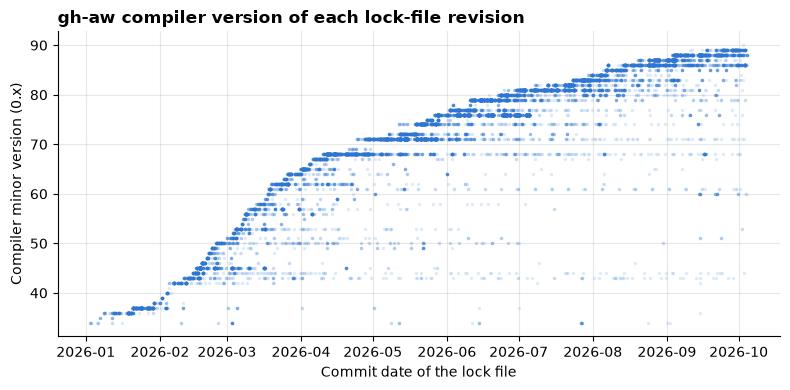

In [6]:
cv = manifests[
    (manifests["artifact_kind"] == "lock") & manifests["compiler_version"].notna()
].copy()
cv["minor"] = cv["compiler_version"].str.extract(r"^\d+\.(\d+)")[0].astype(float)
print(
    f"{cv['compiler_version'].nunique()} compiler versions; "
    f"{manifests.loc[manifests['artifact_kind'] == 'lock', 'compiler_version'].isna().mean():.0%} "
    "of lock revisions do not record one"
)

fig, ax = plt.subplots()
ax.scatter(cv["commit_date"], cv["minor"], s=6, alpha=0.15, color=BLUE, linewidths=0)
ax.set_xlabel("Commit date of the lock file")
ax.set_ylabel("Compiler minor version (0.x)")
ax.set_title("gh-aw compiler version of each lock-file revision")
plt.tight_layout()
plt.show()

## What sources declare

Sources carry the frontmatter: `safe_outputs` (the write actions the agent may request, carried out
by a separate job), `tools`, `network` (`defaults`, `custom`, or nothing), `sandboxed`
(a `sandbox` key is present) and `strict`. Shares are of sources at the snapshot.

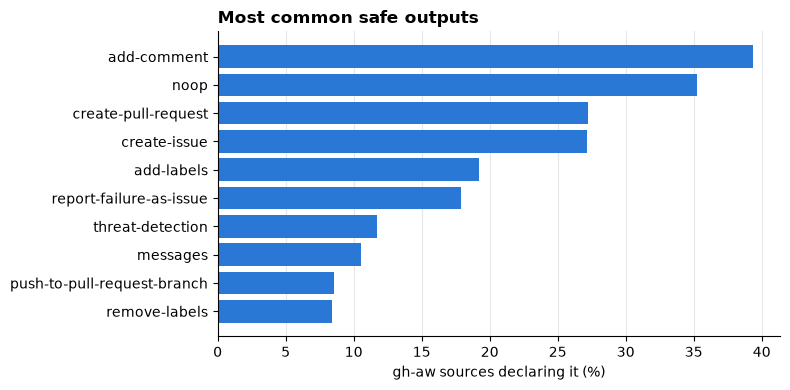

sources declaring no safe output: 6.8%


In [7]:
def share_of(column, frame=source, top=10):
    items = frame[column].dropna().str.split("|").explode()
    return items.value_counts().div(len(frame)).head(top)


safe = share_of("safe_outputs").sort_values()
fig, ax = plt.subplots()
ax.barh(safe.index, 100 * safe.values, color=BLUE)
ax.set_xlabel("gh-aw sources declaring it (%)")
ax.set_title("Most common safe outputs")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"sources declaring no safe output: {source['safe_outputs'].isna().mean():.1%}")

In [8]:
summary = pd.Series(
    {
        "declares tools": source["tools"].notna().mean(),
        "network: defaults": source["network"].eq("defaults").mean(),
        "network: custom": source["network"].eq("custom").mean(),
        "network: not declared": source["network"].isna().mean(),
        "sandboxed": source["sandboxed"].eq(True).mean(),
        "strict: true": source["strict"].eq(True).mean(),
    }
)
display(summary.map("{:.1%}".format).to_frame("share of sources"))
share_of("tools").map("{:.1%}".format).to_frame("most common tools")

,share of sources
declares tools,85.1%
network: defaults,14.0%
network: custom,50.8%
network: not declared,35.2%
sandboxed,2.7%
strict: true,13.8%


,most common tools
tools,
github,76.7%
bash,53.3%
web-fetch,20.1%
edit,15.4%
cache-memory,9.5%
cli-proxy,7.9%
repo-memory,6.8%
agentic-workflows,1.7%
web-search,1.6%


## Reading workflow content

`content.tar.gz` holds every distinct workflow revision as `content/<content_sha256>.yml`.
It is **808 MB**, so the download is behind a flag. The archive is gzip-compressed, which means it
can only be read front to back: `read_contents` streams it once and keeps only the files asked
for, so it needs little memory but takes a minute or two.

In [9]:
DOWNLOAD_CONTENT = True  # set to False to skip the 808 MB download and the cells below
import tarfile


def read_contents(shas):
    """Return {content_sha256: text} for the requested revisions, streaming the archive once."""
    wanted, found = set(shas), {}
    with tarfile.open(fetch("content.tar.gz"), mode="r|gz") as tar:
        for member in tar:
            sha = member.name.rsplit("/", 1)[-1].removesuffix(".yml")
            if sha in wanted:
                found[sha] = tar.extractfile(member).read().decode("utf-8", errors="replace")
                if len(found) == len(wanted):
                    break
    return found

Pick an example: a small, valid workflow at the latest snapshot that calls
`anthropics/claude-code-action`, and look up which job and step invoke it.

In [10]:
candidates = steps[
    (steps["action"] == "anthropics/claude-code-action") & (steps["parse_ok"] == True)
].merge(last[REV + ["n_jobs", "n_steps"]], on=REV)
example = candidates[candidates["n_steps"].between(3, 5)].sort_values(REV).iloc[0]
example[
    [
        "repository",
        "file_path",
        "commit_date",
        "job_id",
        "step_index",
        "action",
        "action_version",
        "triggers",
        "content_sha256",
    ]
]

repository                           0gfoundation/0g-compute-ts-sdk
file_path                  .github/workflows/claude-code-review.yml
commit_date                               2026-02-06 07:23:48+00:00
job_id                                                       claude
step_index                                                      2.0
action                                anthropics/claude-code-action
action_version                                                   v1
triggers          issue_comment|pull_request_review_comment|issu...
content_sha256    4e294aff0672ef9f1d0b4557c74e618aeca3c2b62a579d...
Name: 3974, dtype: object

In [11]:
if DOWNLOAD_CONTENT:
    text = read_contents([example["content_sha256"]])[example["content_sha256"]]
    print("\n".join(text.splitlines()[:40]))

name: Claude Code

on:
  issue_comment:
    types: [created]
  pull_request_review_comment:
    types: [created]
  issues:
    types: [opened, assigned]
  pull_request_review:
    types: [submitted]

jobs:
  claude:
    # Only allow repo members (admin/write/maintain permissions) to trigger
    if: |
      (
        (github.event_name == 'issue_comment' && contains(github.event.comment.body, '@claude')) ||
        (github.event_name == 'pull_request_review_comment' && contains(github.event.comment.body, '@claude')) ||
        (github.event_name == 'pull_request_review' && contains(github.event.review.body, '@claude')) ||
        (github.event_name == 'issues' && (contains(github.event.issue.body, '@claude') || contains(github.event.issue.title, '@claude')))
      )
    runs-on: ubuntu-latest
    permissions:
      contents: write
      pull-requests: write
      issues: write
      id-token: write
      actions: read
    steps:
      - name: Check user permissions
        id: check
   

## Parsing the YAML

PyYAML (pre-installed on Colab) turns the text into dictionaries. One trap: YAML 1.1 reads the
bare key `on` as the boolean `True`, so the triggers are under `doc[True]`. The step marked `<--`
is the agent invocation recorded in `steps` (`job_id`, `step_index`).

In [12]:
import yaml

if DOWNLOAD_CONTENT:
    doc = yaml.safe_load(text)
    print("name:", doc.get("name"))
    print("on:", list(doc.get("on") or doc.get(True) or {}))
    for job_id, job in doc["jobs"].items():
        print(f"\njob {job_id} (runs-on: {job.get('runs-on')})")
        for i, step in enumerate(job.get("steps", [])):
            what = step.get("uses") or (step.get("run") or "").strip().splitlines()[0][:60]
            mark = (
                "  <-- agent"
                if (job_id == example["job_id"] and i == int(example["step_index"]))
                else ""
            )
            print(f"  [{i}] {step.get('name', '')!s:35.35} {what}{mark}")

name: Claude Code
on: ['issue_comment', 'pull_request_review_comment', 'issues', 'pull_request_review']

job claude (runs-on: ubuntu-latest)
  [0] Check user permissions              # Get the username of the user who triggered the action
  [1] Checkout repository                 actions/checkout@v6
  [2] Run Claude Code                     anthropics/claude-code-action@v1  <-- agent


The same approach works for any revision: filter `revisions` or `steps` to the rows you need,
collect their `content_sha256`, and read them in a single pass with `read_contents`. For many files,
extracting the archive once (`tar xzf content.tar.gz`) and opening files by name is faster.